# TP FIA4 – Harmonisation et qualité des données de santé

Notebook reproductible : exploration → schéma cible → harmonisation → contrôles qualité → analyse de la réhospitalisation à 30 jours.

> Données synthétiques : aucun résultat ne doit être interprété comme un résultat clinique.

Placer ce notebook dans le dossier `sujet/` (à côté de `hopital_A.csv`, `hopital_B.csv`, `hopital_C.csv`).

## 0. Imports

In [8]:
import json
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

DOSSIER = os.getcwd()  # le notebook doit être dans le dossier sujet/
SORTIE = os.path.join(DOSSIER, "resultats")
os.makedirs(SORTIE, exist_ok=True)


def titre(texte):
    print("\n" + "=" * 70)
    print(texte)
    print("=" * 70)

In [7]:
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


## 1. CHARGEMENT ET EXPLORATION DES 3 SOURCES

On charge les 3 fichiers en texte (`dtype=str`) pour garder les valeurs brutes, puis on regarde la taille, les colonnes, les manquants et les doublons.

In [ ]:
titre("1. Chargement et exploration")

# On lit tout en texte (dtype=str) pour ne rien perdre avant de convertir nous-mêmes
A = pd.read_csv(os.path.join(DOSSIER, "hopital_A.csv"), dtype=str)
B = pd.read_csv(os.path.join(DOSSIER, "hopital_B.csv"), dtype=str)
C = pd.read_csv(os.path.join(DOSSIER, "hopital_C.csv"), dtype=str)

for nom, df in [("A", A), ("B", B), ("C", C)]:
    print(f"\nHôpital {nom} : {df.shape[0]} lignes, {df.shape[1]} colonnes")
    print("Colonnes :", list(df.columns))
    print("Valeurs manquantes :", int(df.isna().sum().sum()))
    print("Lignes dupliquées :", int(df.duplicated().sum()))
    print("Identifiants dupliqués :", int(df.iloc[:, 0].duplicated().sum()))
    


1. Chargement et exploration

Hôpital A : 3925 lignes, 18 colonnes
Colonnes : ['id', 'date_adm', 'date_dis', 'age', 'gender', 'weight', 'height_m', 'smoker', 'diabetes', 'hypertension', 'icu', 'los', 'readmit30', 'death', 'diag', 'sbp', 'creatinine', 'crp']
Valeurs manquantes : 1711
Lignes dupliquées : 0
Identifiants dupliqués : 0

Hôpital B : 3497 lignes, 18 colonnes
Colonnes : ['patient', 'admit', 'discharge', 'age', 'gender', 'weight_lb', 'height_cm', 'smoking', 'diab', 'htn', 'icu', 'stay_days', 'readmission', 'mortality', 'diagnosis', 'blood_pressure', 'creat', 'CRP']
Valeurs manquantes : 2367
Lignes dupliquées : 0
Identifiants dupliqués : 0

Hôpital C : 2578 lignes, 18 colonnes
Colonnes : ['id_patient', 'date_entree', 'date_sortie', 'age', 'sexe', 'poids', 'taille', 'tabac', 'diabete', 'hta', 'reanimation', 'duree', 'rehosp_30j', 'deces', 'diag', 'pas', 'creatininémie', 'CRP']
Valeurs manquantes : 2710
Lignes dupliquées : 0
Identifiants dupliqués : 0


## 2. SCHÉMA CIBLE COMMUN : on renomme les colonnes des 3 hôpitaux

Chaque hôpital a ses propres noms de colonnes. On les renomme vers un **schéma cible commun** et on ajoute la colonne `hopital` pour la traçabilité.

In [22]:
titre("2. Renommage vers le schéma cible")

renommage_A = {
    "id": "id_patient", "date_adm": "date_entree", "date_dis": "date_sortie",
    "gender": "sexe", "weight": "poids_kg", "height_m": "taille_cm",
    "smoker": "tabac", "diabetes": "diabete", "hypertension": "hta",
    "icu": "reanimation", "los": "duree_sejour", "readmit30": "rehosp_30j",
    "death": "deces", "diag": "diag", "sbp": "pas",
    "creatinine": "creatinine", "crp": "crp",
}
renommage_B = {
    "patient": "id_patient", "admit": "date_entree", "discharge": "date_sortie",
    "gender": "sexe", "weight_lb": "poids_kg", "height_cm": "taille_cm",
    "smoking": "tabac", "diab": "diabete", "htn": "hta", "icu": "reanimation",
    "stay_days": "duree_sejour", "readmission": "rehosp_30j",
    "mortality": "deces", "diagnosis": "diag", "blood_pressure": "pas",
    "creat": "creatinine", "CRP": "crp",
}
renommage_C = {
    "taille": "taille_cm", "poids": "poids_kg", "duree": "duree_sejour",
    "creatininémie": "creatinine", "CRP": "crp",
}

A = A.rename(columns=renommage_A)
B = B.rename(columns=renommage_B)
C = C.rename(columns=renommage_C)

# On garde la trace de l'hôpital d'origine (important pour l'analyse et la traçabilité)
A["hopital"] = "A"
B["hopital"] = "B"
C["hopital"] = "C"
print("example d'un hopitale ",list(A.columns))
print(C)


2. Renommage vers le schéma cible
example d'un hopitale  ['id_patient', 'date_entree', 'date_sortie', 'age', 'sexe', 'poids_kg', 'taille_cm', 'tabac', 'diabete', 'hta', 'reanimation', 'duree_sejour', 'rehosp_30j', 'deces', 'diag', 'pas', 'creatinine', 'crp', 'hopital']
     id_patient date_entree date_sortie   age   sexe poids_kg taille_cm tabac  \
0       P100010  2025/12/02  2025/12/05  54.0  Homme     67.1      1.84   NON   
1       P100012  2024/04/26  2024/04/27  66.0  Homme     90.2      1.88   NON   
2       P100013  2024/07/10  2024/07/11  28.0  Homme     73.4      1.81   OUI   
3       P100017  2024/08/08  2024/08/13  68.0  Homme     56.3      1.92   NON   
4       P100022  2024/02/20  2024/02/21  63.0  Homme     87.7      1.76   NON   
...         ...         ...         ...   ...    ...      ...       ...   ...   
2573    P109977  2025/07/19  2025/07/27  46.0      H     87.6     168.0   NON   
2574    P109978  2024/04/02  2024/04/07  44.0      F     76.4     176.0   OUI   


## 3. HARMONISATION HÔPITAL PAR HÔPITAL (ce qui dépend de la source)

Traitements qui dépendent de la source : formats de dates, unités de poids et de taille, codes « non mesuré » dans la pression artérielle.

In [ ]:
titre("3. Harmonisation spécifique à chaque source")


3. Harmonisation spécifique à chaque source


### 3.1 Dates : 3 formats différents -> format ISO 8601 (AAAA-MM-JJ)

In [23]:
formats_dates = {"A": "%Y-%m-%d", "B": "%d/%m/%Y", "C": "%Y/%m/%d"}
for df in [A, B, C]:
    fmt = formats_dates[df["hopital"].iloc[0]]
    for col in ["date_entree", "date_sortie"]:
        df[col] = pd.to_datetime(df[col], format=fmt, errors="coerce")

### 3.2 Poids : vérification des unités

In [ ]:
# Dans notre brainstorming on avait remarqué des poids "trop longs"
# (ex : 145.7238155555). En regardant de plus près, ce ne sont pas juste des
# arrondis : ce sont des valeurs écrites dans la MAUVAISE unité.
#   - A (censé être en kg) : 20 valeurs à longues décimales ~ 96-206 -> en livres
#   - B (censé être en lb) : 20 valeurs à longues décimales ~ 40-97  -> déjà en kg
def decimales_longues(serie):
    """True si la valeur a plus de 2 chiffres après la virgule."""
    partie_dec = serie.str.split(".").str[1].fillna("")
    return partie_dec.str.len() > 2

LB_EN_KG = 0.453592

for df in [A, B, C]:
    df["poids_unite_corrigee"] = 0

# Hôpital A : kg, sauf valeurs à longues décimales = livres
masque = decimales_longues(A["poids_kg"])
A["poids_kg"] = pd.to_numeric(A["poids_kg"], errors="coerce")
A.loc[masque, "poids_kg"] = A.loc[masque, "poids_kg"] * LB_EN_KG
A.loc[masque, "poids_unite_corrigee"] = 1
print(f"A : {masque.sum()} poids en livres convertis en kg")

# Hôpital B : livres, sauf valeurs à longues décimales = déjà en kg
masque = decimales_longues(B["poids_kg"])
B["poids_kg"] = pd.to_numeric(B["poids_kg"], errors="coerce")
B.loc[~masque, "poids_kg"] = B.loc[~masque, "poids_kg"] * LB_EN_KG
B.loc[masque, "poids_unite_corrigee"] = 1
print(f"B : {(~masque).sum()} poids convertis lb -> kg, "
      f"{masque.sum()} déjà en kg laissés tels quels")

C["poids_kg"] = pd.to_numeric(C["poids_kg"], errors="coerce")



A : 20 poids en livres convertis en kg
B : 3477 poids convertis lb -> kg, 20 déjà en kg laissés tels quels


### 3.3 Taille : tout en cm

In [ ]:
A["taille_cm"] = pd.to_numeric(A["taille_cm"], errors="coerce") * 100   # m -> cm
B["taille_cm"] = pd.to_numeric(B["taille_cm"], errors="coerce")
C["taille_cm"] = pd.to_numeric(C["taille_cm"], errors="coerce")
masque = C["taille_cm"] < 3          # quelques tailles saisies en mètres
C.loc[masque, "taille_cm"] = C.loc[masque, "taille_cm"] * 100
print(f"C : {masque.sum()} tailles en mètres converties en cm")

C : 15 tailles en mètres converties en cm


### 3.4 Pression artérielle : valeurs "codes" qui ne sont pas des mesures

In [ ]:
# Chaque hôpital a SA valeur bidon répétée 10 fois : -1 (A), 999 (B), 35 (C).
# Ce sont des codes "non mesuré" -> on les remplace par NaN (≠ 0 !)
codes_pas = {"A": -1, "B": 999, "C": 35}
for df in [A, B, C]:
    code = codes_pas[df["hopital"].iloc[0]]
    df["pas"] = pd.to_numeric(df["pas"], errors="coerce")
    n = (df["pas"] == code).sum()
    df.loc[df["pas"] == code, "pas"] = np.nan
    print(f"{df['hopital'].iloc[0]} : {n} PAS = {code} remplacées par NaN")

A : 10 PAS = -1 remplacées par NaN
B : 10 PAS = 999 remplacées par NaN
C : 10 PAS = 35 remplacées par NaN


## 4. ASSEMBLAGE + HARMONISATION COMMUNE

On assemble les 3 hôpitaux puis on harmonise ce qui est commun : sexe, variables oui/non, types numériques, créatinine, durée de séjour, diagnostics et IMC.

In [ ]:
titre("4. Assemblage des 3 hôpitaux")

colonnes_finales = [
    "id_patient", "hopital", "date_entree", "date_sortie", "age", "sexe",
    "poids_kg", "taille_cm", "tabac", "diabete", "hta", "reanimation",
    "duree_sejour", "rehosp_30j", "deces", "diag", "pas", "creatinine", "crp",
    "poids_unite_corrigee",
]
df = pd.concat([A[colonnes_finales], B[colonnes_finales], C[colonnes_finales]],
               ignore_index=True)
print("Taille du jeu fusionné :", df.shape)

# Unicité des patients entre hôpitaux
print("Identifiants en double entre hôpitaux :", df["id_patient"].duplicated().sum())


4. Assemblage des 3 hôpitaux
Taille du jeu fusionné : (10000, 20)
Identifiants en double entre hôpitaux : 0


### 4.1 Sexe : M/F (Male, Female, Homme, H...)

In [ ]:
correspondance_sexe = {"M": "M", "MALE": "M", "H": "M", "HOMME": "M",
                       "F": "F", "FEMALE": "F", "FEMME": "F"}
df["sexe"] = df["sexe"].str.strip().str.upper().map(correspondance_sexe)
print("Sexe :", df["sexe"].value_counts(dropna=False).to_dict()) ##il faut ajouter le oneHOtEncoding parce que c'est un variables categorial

Sexe : {'M': 4905, 'F': 4680, nan: 415}


### 4.2 Variables oui/non -> 1/0 (yes/no, Y/N, OUI/NON, 0.0/1.0)

In [ ]:
# On choisit 1/0 (entier) : lisible par la machine et pratique pour les moyennes
correspondance_binaire = {"YES": 1, "Y": 1, "OUI": 1, "1": 1, "1.0": 1,
                          "NO": 0, "N": 0, "NON": 0, "0": 0, "0.0": 0}
binaires = ["tabac", "diabete", "hta", "reanimation", "rehosp_30j", "deces"]
for col in binaires:
    df[col] = df[col].str.strip().str.upper().map(correspondance_binaire).astype("Int64")

### 4.3 Numériques

In [ ]:
for col in ["age", "duree_sejour", "creatinine", "crp"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df["age"] = df["age"].round().astype("Int64")            # âge = entier
df["poids_kg"] = df["poids_kg"].round(1)                  # 1 décimale suffit
df["taille_cm"] = df["taille_cm"].round().astype("Int64")

# Créatinine : mg/dL -> µmol/L (unité utilisée en France), 1 mg/dL = 88.4 µmol/L
df["creatinine_umol_l"] = (df["creatinine"] * 88.4).round(0)
df = df.drop(columns="creatinine")

### 4.4 Durée de séjour

In [ ]:
#completer la valeur manquantes à partir  de durées de séjour   pour diminuer les NAN   
# Vérification de cohérence : duree_sejour ≈ date_sortie - date_entree
ecart_dates = (df["date_sortie"] - df["date_entree"]).dt.days
print("Sorties avant entrées :", int((ecart_dates < 0).sum()))
print("Écart duree_sejour - dates (jours) :",
      (df["duree_sejour"] - ecart_dates).describe().round(2).to_dict())
# -> la durée est toujours égale à l'écart des dates + une fraction de jour (0 à 0.9).
#    On GARDE la valeur décimale (plus précise que l'arrondi entier)
#    et on complète les durées manquantes à partir des dates quand c'est possible.
manque = df["duree_sejour"].isna() & ecart_dates.notna()
df.loc[manque, "duree_sejour"] = ecart_dates[manque]
df["duree_completee"] = manque.astype(int)
print(f"Durées de séjour complétées à partir des dates : {manque.sum()}")

Sorties avant entrées : 0
Écart duree_sejour - dates (jours) : {'count': 8838.0, 'mean': 0.43, 'std': 0.29, 'min': 0.0, '25%': 0.2, '50%': 0.4, '75%': 0.7, 'max': 0.9}
Durées de séjour complétées à partir des dates : 368


### 4.5 Diagnostic : codes harmonisés en CIM-10

In [ ]:
# A : I10, E11.9, E11.9+I10 | B : HTA, DM2, DM2|HTA | C : HTA, E11, E11/HTA
def harmoniser_diag(valeur):
    if pd.isna(valeur):
        return np.nan #if la case est vide on la laisse vide 
    codes = []
    for morceau in str(valeur).replace("|", "+").replace("/", "+").split("+"): #"DM2|HTA" devient "DM2+HTA"
        morceau = morceau.strip().upper()
        if morceau in ["HTA", "I10"]:
            codes.append("I10")
        elif morceau in ["DM2", "E11", "E11.9"]:
            codes.append("E11")   #"DM2" → "E11", "HTA" → "I10". Donc codes = ["E11", "I10"].
    return "+".join(sorted(set(codes))) #set enlève les doublons (si un code apparaît deux fois),  E11+I10 et I10+E11 deviennent la même chose,

df["diag"] = df["diag"].apply(harmoniser_diag)
print("Diagnostics harmonisés :", df["diag"].value_counts(dropna=False).to_dict())

# Table séparée des diagnostics (idée du brainstorming) : une ligne = un code.
# "E11+I10" n'est pas atomique, on l'éclate en 2 lignes.
table_diag = df[["id_patient", "diag"]].dropna().copy()
table_diag["code_diag"] = table_diag["diag"].str.split("+")
table_diag = table_diag.explode("code_diag")
table_diag["libelle"] = table_diag["code_diag"].map(
    {"E11": "Diabète de type 2", "I10": "Hypertension essentielle"})
table_diag = table_diag.drop(columns="diag")



Diagnostics harmonisés : {'I10': 5009, 'E11': 3941, 'E11+I10': 645, nan: 405}


### 4.6 IMC (variable dérivée)

In [ ]:
# Attention : l'IMC est redondant avec poids et taille (vu en cours).
# On le calcule pour l'analyse, mais on ne l'utilise pas EN MÊME TEMPS que poids/taille.
df["imc"] = (df["poids_kg"] / (df["taille_cm"] / 100) ** 2).round(1)

## 5. CONTRÔLES QUALITÉ (cohérence, valeurs suspectes)

On vérifie la cohérence des données. Les valeurs suspectes sont **signalées** par des colonnes 0/1, pas supprimées.

In [ ]:
titre("5. Contrôles qualité")


5. Contrôles qualité


### 5.1 Diagnostic vs indicateurs diabete/hta : sont-ils cohérents ?

In [ ]:
diag_dit_diabete = df["diag"].str.contains("E11", na=False)
diag_dit_hta = df["diag"].str.contains("I10", na=False)
print("\nTableau croisé diag x (diabete, hta) :")
print(pd.crosstab(df["diag"], [df["diabete"], df["hta"]]))
# Constat : un patient SANS diabète ni HTA reçoit le code I10 (HTA),
# et un patient avec HTA seule reçoit E11 (diabète). Le champ diag est donc
# incohérent avec les indicateurs. Pour l'analyse on se base sur diabete/hta
# (renseignés de façon homogène dans les 3 hôpitaux), et on signale diag.
df["diag_incoherent"] = (
    (diag_dit_diabete != (df["diabete"] == 1)) | (diag_dit_hta != (df["hta"] == 1))
) & df["diag"].notna() & df["diabete"].notna() & df["hta"].notna()
df["diag_incoherent"] = df["diag_incoherent"].astype(int)
print("Lignes où diag contredit diabete/hta :", df["diag_incoherent"].sum())


Tableau croisé diag x (diabete, hta) :
diabete     0           1     
hta         0     1     0    1
diag                          
E11         0  2468  1173    0
E11+I10     0     0     0  590
I10      4608     0     0    0
Lignes où diag contredit diabete/hta : 7076


### 5.2 Valeurs "plafond / plancher" répétées (troncature probable à la saisie)

In [ ]:
print("\nÂge = 95 :", (df["age"] == 95).sum(), "(pic anormal, âge probablement plafonné)")
print("Poids = 40 kg :", (df["poids_kg"] == 40).sum(), "(pic anormal, poids probablement plancher)")
df["age_plafonne"] = (df["age"] == 95).fillna(False).astype(int)
df["poids_plancher"] = (df["poids_kg"] == 40).fillna(False).astype(int)


Âge = 95 : 342 (pic anormal, âge probablement plafonné)
Poids = 40 kg : 111 (pic anormal, poids probablement plancher)


### 5.3 Valeurs hors bornes physiologiques -> signalées (pas supprimées)

In [ ]:
bornes = {"pas": (60, 260), "imc": (12, 70), "crp": (0, 500),
          "creatinine_umol_l": (20, 1500), "duree_sejour": (0, 365)}
for col, (mini, maxi) in bornes.items():
    hors = ((df[col] < mini) | (df[col] > maxi)).sum()
    print(f"{col} hors [{mini}, {maxi}] : {hors}")

pas hors [60, 260] : 0
imc hors [12, 70] : 22
crp hors [0, 500] : 0
creatinine_umol_l hors [20, 1500] : 0
duree_sejour hors [0, 365] : 0


### 5.4 Outliers statistiques avec la règle IQR (vue en cours) - on les SIGNALE

In [ ]:
def outliers_iqr(serie):
    q1, q3 = serie.quantile(0.25), serie.quantile(0.75)
    iqr = q3 - q1
    return (serie < q1 - 1.5 * iqr) | (serie > q3 + 1.5 * iqr)

for col in ["poids_kg", "imc", "pas", "creatinine_umol_l", "crp", "duree_sejour"]:
    print(f"Outliers IQR {col} : {outliers_iqr(df[col]).sum()}")
# CRP et durée ont beaucoup d'outliers IQR : c'est normal, ces variables sont
# asymétriques (inflammation, longs séjours). On ne les supprime pas.

Outliers IQR poids_kg : 25
Outliers IQR imc : 74
Outliers IQR pas : 71
Outliers IQR creatinine_umol_l : 247
Outliers IQR crp : 710
Outliers IQR duree_sejour : 303


### 5.5 Incohérence décès / réhospitalisation

In [ ]:
incoh = ((df["deces"] == 1) & (df["rehosp_30j"] == 1)).fillna(False).sum()
print(f"\nPatients décédés ET réhospitalisés : {incoh} (impossible -> signalés)")
df["deces_et_rehosp"] = ((df["deces"] == 1) & (df["rehosp_30j"] == 1)).fillna(False).astype(int)


Patients décédés ET réhospitalisés : 17 (impossible -> signalés)


## 6. PROFIL QUALITÉ (données manquantes)

Proportion de données manquantes par colonne et par hôpital, avec la carte des manquants vue en cours.


6. Profil qualité
                             type  nb_manquants  pct_manquants  \
date_entree        datetime64[us]           402            4.0   
date_sortie        datetime64[us]           406            4.1   
age                         Int64           352            3.5   
sexe                          str           415            4.2   
poids_kg                  float64           449            4.5   
taille_cm                   Int64           382            3.8   
imc                       Float64           815            8.2   
tabac                       Int64           377            3.8   
diabete                     Int64           401            4.0   
hta                         Int64           408            4.1   
reanimation                 Int64           399            4.0   
duree_sejour              float64            34            0.3   
rehosp_30j                  Int64           397            4.0   
deces                       Int64           390          

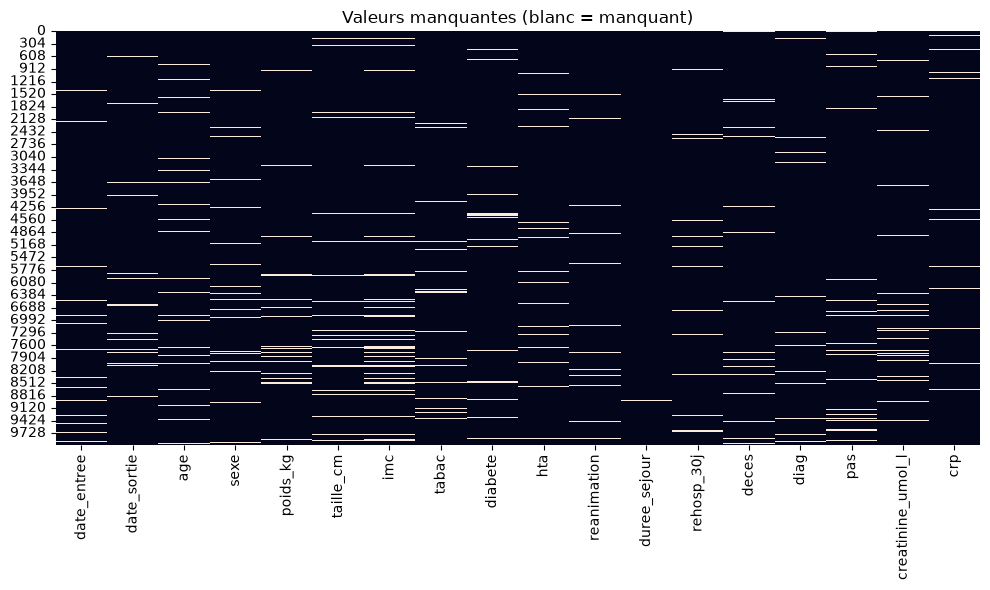


Lignes 100% complètes : 5319 / 10000 (53.2 %)


In [ ]:
titre("6. Profil qualité")

colonnes_metier = ["date_entree", "date_sortie", "age", "sexe", "poids_kg",
                   "taille_cm", "imc", "tabac", "diabete", "hta", "reanimation",
                   "duree_sejour", "rehosp_30j", "deces", "diag", "pas",
                   "creatinine_umol_l", "crp"]

profil = pd.DataFrame({
    "type": df[colonnes_metier].dtypes.astype(str),
    "nb_manquants": df[colonnes_metier].isna().sum(),
    "pct_manquants": (df[colonnes_metier].isna().mean() * 100).round(1),
    "nb_valeurs_distinctes": df[colonnes_metier].nunique(),
})
# % de manquants par hôpital (est-ce qu'un hôpital est moins bien renseigné ?)
for h in ["A", "B", "C"]:
    sous = df[df["hopital"] == h]
    profil[f"pct_manquants_{h}"] = (sous[colonnes_metier].isna().mean() * 100).round(1)
print(profil)

# Carte des manquants (comme dans le cours : heatmap de isna)
plt.figure(figsize=(10, 6))
sns.heatmap(df[colonnes_metier].isna(), cbar=False)
plt.title("Valeurs manquantes (blanc = manquant)")
plt.tight_layout()
plt.savefig(os.path.join(SORTIE, "fig_manquants.png"), dpi=120)
plt.show()

lignes_completes = df[colonnes_metier].dropna().shape[0]
print(f"\nLignes 100% complètes : {lignes_completes} / {len(df)} "
      f"({lignes_completes / len(df) * 100:.1f} %)")
# -> Supprimer toute ligne incomplète ferait perdre beaucoup de patients.
#    Choix : on garde toutes les lignes et on fait chaque analyse
#    sur les lignes où les variables utilisées sont renseignées.

## 7. ANALYSE ÉPIDÉMIOLOGIQUE : RÉHOSPITALISATION À 30 JOURS

Analyse de la réhospitalisation à 30 jours sur les patients vivants à la sortie : taux, odds ratio, tests du Chi² et de Mann-Whitney, impact des données manquantes.

In [ ]:
titre("7. Analyse de la réhospitalisation à 30 jours")

# Population : patients vivants à la sortie et rehosp_30j connue
# (un patient décédé ne peut pas être réhospitalisé)
pop = df[(df["deces"] == 0) & df["rehosp_30j"].notna()].copy()
pop["rehosp_30j"] = pop["rehosp_30j"].astype(int)
taux_global = pop["rehosp_30j"].mean() * 100
print(f"Population analysée : {len(pop)} patients")
print(f"Taux global de réhospitalisation : {taux_global:.1f} %")
print("Équilibre des classes :", pop["rehosp_30j"].value_counts().to_dict(),
      "-> classes très déséquilibrées (à prendre en compte pour un futur modèle)")

# Groupes d'âge et d'IMC pour lire plus facilement
pop["classe_age"] = pd.cut(pop["age"].astype(float), bins=[17, 40, 60, 75, 120],
                           labels=["18-40", "41-60", "61-75", ">75"])
pop["classe_duree"] = pd.cut(pop["duree_sejour"], bins=[0, 3, 7, 14, 400],
                             labels=["<=3j", "4-7j", "8-14j", ">14j"])


7. Analyse de la réhospitalisation à 30 jours
Population analysée : 9009 patients
Taux global de réhospitalisation : 8.5 %
Équilibre des classes : {0: 8246, 1: 763} -> classes très déséquilibrées (à prendre en compte pour un futur modèle)


### 7.1 Variables binaires : taux, odds ratio, test du Chi²

In [ ]:
def analyse_binaire(data, var):
    sous = data[[var, "rehosp_30j"]].dropna()
    tab = pd.crosstab(sous[var], sous["rehosp_30j"])
    # odds ratio = (a*d)/(b*c) avec +0.5 pour éviter une division par 0
    a, b = tab.loc[1, 1] + 0.5, tab.loc[1, 0] + 0.5
    c, d = tab.loc[0, 1] + 0.5, tab.loc[0, 0] + 0.5
    odds_ratio = (a * d) / (b * c)
    chi2, p, _, _ = stats.chi2_contingency(tab)
    return {
        "variable": var,
        "n": len(sous),
        "taux_si_0 (%)": round(sous.loc[sous[var] == 0, "rehosp_30j"].mean() * 100, 1),
        "taux_si_1 (%)": round(sous.loc[sous[var] == 1, "rehosp_30j"].mean() * 100, 1),
        "odds_ratio": round(odds_ratio, 2),
        "p_value_chi2": round(p, 4),
    }

resultats_binaires = pd.DataFrame(
    [analyse_binaire(pop, v) for v in ["diabete", "hta", "tabac", "reanimation"]]
)
pop["sexe_h"] = (pop["sexe"] == "M").astype("Int64").where(pop["sexe"].notna())
resultats_binaires = pd.concat(
    [resultats_binaires, pd.DataFrame([analyse_binaire(pop, "sexe_h")])],
    ignore_index=True)
print("\nFacteurs binaires :")
print(resultats_binaires.to_string(index=False))


Facteurs binaires :
   variable    n  taux_si_0 (%)  taux_si_1 (%)  odds_ratio  p_value_chi2
    diabete 8649            8.2            9.9        1.24        0.0243
        hta 8654            7.3           10.4        1.48        0.0000
      tabac 8664            8.5            8.3        0.98        0.8065
reanimation 8655            8.2            9.9        1.24        0.0875
     sexe_h 8631            8.4            8.8        1.06        0.4840


### 7.2 Variables continues : moyenne réhospitalisés vs non

In [ ]:
# Test de Mann-Whitney (ne suppose pas une distribution normale)
lignes = []
for var in ["age", "duree_sejour", "imc", "pas", "creatinine_umol_l", "crp"]:
    sous = pop[[var, "rehosp_30j"]].dropna()
    g1 = sous.loc[sous["rehosp_30j"] == 1, var].astype(float)
    g0 = sous.loc[sous["rehosp_30j"] == 0, var].astype(float)
    _, p = stats.mannwhitneyu(g1, g0)
    lignes.append({"variable": var, "n": len(sous),
                   "moyenne_rehosp": round(g1.mean(), 1),
                   "moyenne_non_rehosp": round(g0.mean(), 1),
                   "p_value_mann_whitney": round(p, 4)})
resultats_continus = pd.DataFrame(lignes)
print("\nFacteurs continus :")
print(resultats_continus.to_string(index=False))


Facteurs continus :
         variable    n  moyenne_rehosp  moyenne_non_rehosp  p_value_mann_whitney
              age 8694            61.3                61.8                0.5650
     duree_sejour 8979             5.5                 5.0                0.0000
              imc 8282            26.1                26.7                0.0122
              pas 8619           136.5               135.4                0.2091
creatinine_umol_l 8657            93.6                92.8                0.3277
              crp 8631            18.2                18.0                0.9681


### 7.3 Durée de séjour et diabète (questions de l'énoncé)

In [ ]:
taux_par_duree = (pop.groupby("classe_duree", observed=True)["rehosp_30j"]
                  .agg(n="count", taux="mean"))
taux_par_duree["taux"] = (taux_par_duree["taux"] * 100).round(1)
print("\nTaux par durée de séjour :\n", taux_par_duree)

taux_par_age = (pop.groupby("classe_age", observed=True)["rehosp_30j"]
                .agg(n="count", taux="mean"))
taux_par_age["taux"] = (taux_par_age["taux"] * 100).round(1)
print("\nTaux par classe d'âge :\n", taux_par_age)

taux_par_hopital = (pop.groupby("hopital")["rehosp_30j"]
                    .agg(n="count", taux="mean"))
taux_par_hopital["taux"] = (taux_par_hopital["taux"] * 100).round(1)
print("\nTaux par hôpital :\n", taux_par_hopital)


Taux par durée de séjour :
                  n  taux
classe_duree            
<=3j          2630   7.3
4-7j          4453   8.1
8-14j         1754  11.0
>14j           142  12.0

Taux par classe d'âge :
                n  taux
classe_age            
18-40       1011  11.0
41-60       3027   7.6
61-75       2714   8.1
>75         1942   8.8

Taux par hôpital :
             n  taux
hopital            
A        3642   8.3
B        3142   9.0
C        2225   8.0


### 7.4 Impact des données manquantes

In [ ]:
# On compare le taux "toutes lignes" avec le taux "lignes complètes uniquement"
complet = pop.dropna(subset=["age", "sexe", "tabac", "diabete", "hta",
                             "reanimation", "duree_sejour", "pas",
                             "creatinine_umol_l", "crp", "imc"])
taux_complet = complet["rehosp_30j"].mean() * 100
# Les patients sans rehosp_30j sont-ils différents ? (manquant au hasard ?)
manque_rehosp = df[df["rehosp_30j"].isna()]
print(f"\nCas complets : {len(complet)} / {len(pop)} patients "
      f"({len(complet) / len(pop) * 100:.1f} %)")
print(f"Taux toutes lignes : {taux_global:.1f} % | cas complets : {taux_complet:.1f} %")
print(f"Patients avec rehosp_30j manquante : {len(manque_rehosp)} "
      f"(âge moyen {manque_rehosp['age'].mean():.1f} vs {df['age'].mean():.1f})")


Cas complets : 5807 / 9009 patients (64.5 %)
Taux toutes lignes : 8.5 % | cas complets : 8.5 %
Patients avec rehosp_30j manquante : 397 (âge moyen 61.4 vs 61.7)


### 7.5 Figures

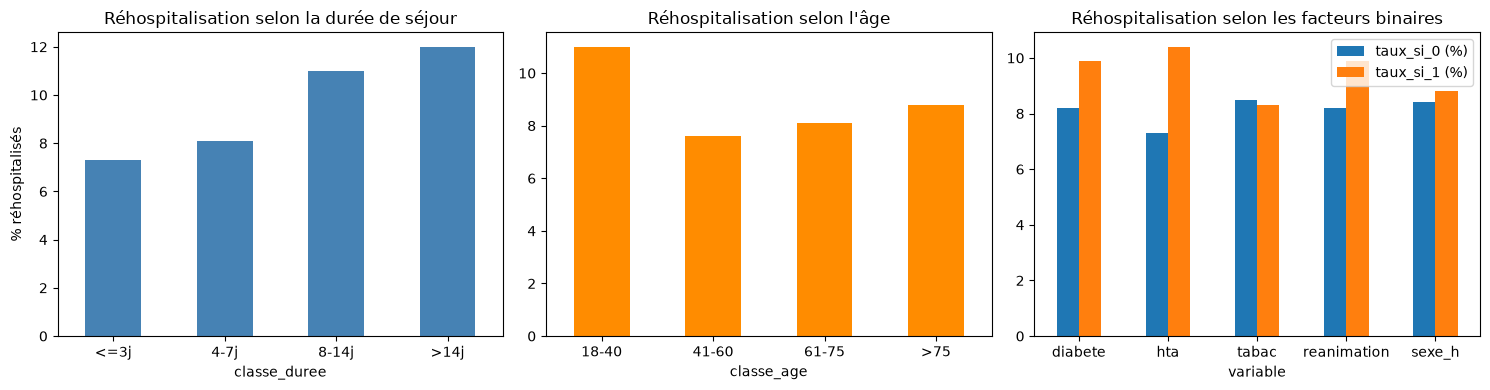

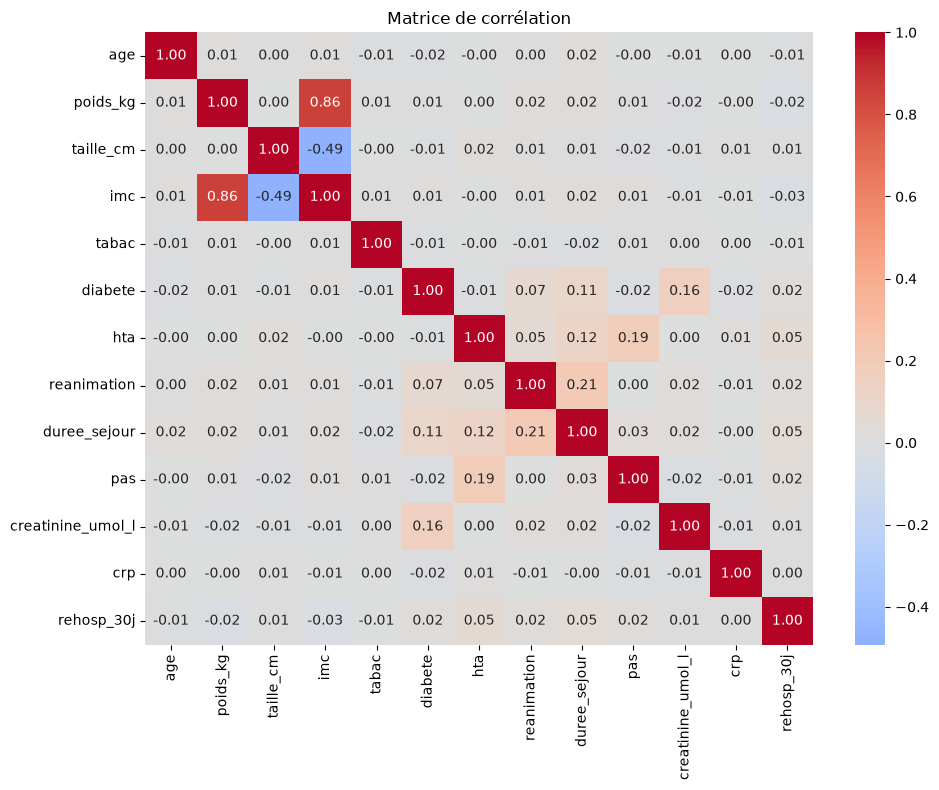

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
(taux_par_duree["taux"]).plot.bar(ax=axes[0], color="steelblue")
axes[0].set_title("Réhospitalisation selon la durée de séjour")
axes[0].set_ylabel("% réhospitalisés")
(taux_par_age["taux"]).plot.bar(ax=axes[1], color="darkorange")
axes[1].set_title("Réhospitalisation selon l'âge")
diab = resultats_binaires.set_index("variable")[["taux_si_0 (%)", "taux_si_1 (%)"]]
diab.plot.bar(ax=axes[2])
axes[2].set_title("Réhospitalisation selon les facteurs binaires")
for ax in axes:
    ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.savefig(os.path.join(SORTIE, "fig_rehospitalisation.png"), dpi=120)
plt.show()

# Matrice de corrélation (outil vu en cours pour la sélection de variables)
corr_cols = ["age", "poids_kg", "taille_cm", "imc", "tabac", "diabete", "hta",
             "reanimation", "duree_sejour", "pas", "creatinine_umol_l", "crp",
             "rehosp_30j"]
corr = df[corr_cols].astype(float).corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Matrice de corrélation")
plt.tight_layout()
plt.savefig(os.path.join(SORTIE, "fig_correlation.png"), dpi=120)
plt.show()

## 8. EXPORTS

Export des livrables dans `resultats/`.

In [ ]:
titre("8. Exports")

# Dates au format ISO dans le CSV
export = df.copy()
for col in ["date_entree", "date_sortie"]:
    export[col] = export[col].dt.strftime("%Y-%m-%d")

ordre = ["id_patient", "hopital", "date_entree", "date_sortie", "duree_sejour",
         "age", "sexe", "poids_kg", "taille_cm", "imc", "tabac", "diabete", "hta",
         "reanimation", "rehosp_30j", "deces", "diag", "pas",
         "creatinine_umol_l", "crp",
         # colonnes de traçabilité / qualité
         "poids_unite_corrigee", "duree_completee", "diag_incoherent",
         "age_plafonne", "poids_plancher", "deces_et_rehosp"]
export[ordre].to_csv(os.path.join(SORTIE, "patients_harmonises.csv"), index=False)
table_diag.to_csv(os.path.join(SORTIE, "diagnostics.csv"), index=False)
profil.to_csv(os.path.join(SORTIE, "profil_qualite.csv"))

# Schéma cible commun : nom, type, unité, et nom d'origine dans chaque hôpital
inverse = lambda d: {v: k for k, v in d.items()}
def noms_origine(fichier, renommage):
    colonnes = pd.read_csv(os.path.join(DOSSIER, fichier), nrows=0).columns
    return {**{c: c for c in colonnes}, **inverse(renommage)}
iA = noms_origine("hopital_A.csv", renommage_A)
iB = noms_origine("hopital_B.csv", renommage_B)
iC = noms_origine("hopital_C.csv", renommage_C)
description = {
    "id_patient": ("texte", "-", "Identifiant unique du patient"),
    "hopital": ("texte", "A/B/C", "Établissement d'origine (ajouté)"),
    "date_entree": ("date", "AAAA-MM-JJ", "Date d'admission"),
    "date_sortie": ("date", "AAAA-MM-JJ", "Date de sortie"),
    "duree_sejour": ("décimal", "jours", "Durée de séjour"),
    "age": ("entier", "années", "Âge"),
    "sexe": ("texte", "M/F", "Sexe"),
    "poids_kg": ("décimal", "kg", "Poids"),
    "taille_cm": ("entier", "cm", "Taille"),
    "imc": ("décimal", "kg/m²", "IMC calculé = poids / taille² (dérivé)"),
    "tabac": ("entier", "0/1", "Fumeur"),
    "diabete": ("entier", "0/1", "Diabète"),
    "hta": ("entier", "0/1", "Hypertension artérielle"),
    "reanimation": ("entier", "0/1", "Passage en réanimation"),
    "rehosp_30j": ("entier", "0/1", "Réhospitalisation à 30 jours"),
    "deces": ("entier", "0/1", "Décès à l'hôpital"),
    "diag": ("texte", "CIM-10", "Diagnostic principal (E11, I10, E11+I10)"),
    "pas": ("décimal", "mmHg", "Pression artérielle systolique"),
    "creatinine_umol_l": ("décimal", "µmol/L", "Créatinine (convertie depuis mg/dL)"),
    "crp": ("décimal", "mg/L", "Protéine C-réactive"),
}
schema = pd.DataFrame([
    {"variable": v, "type": t, "unite_format": u, "description": d,
     "source_A": iA.get(v, "creatinine" if v == "creatinine_umol_l" else "-"),
     "source_B": iB.get(v, "creat" if v == "creatinine_umol_l" else "-"),
     "source_C": iC.get(v, "creatininémie" if v == "creatinine_umol_l" else "-")}
    for v, (t, u, d) in description.items()
])
schema.loc[schema["variable"] == "imc", ["source_A", "source_B", "source_C"]] = "calculé"
schema.loc[schema["variable"] == "hopital", ["source_A", "source_B", "source_C"]] = "ajouté"
schema.to_csv(os.path.join(SORTIE, "schema_cible.csv"), index=False)

# Résultats d'analyse en JSON (pour le rapport)
resultats = {
    "n_total": int(len(df)),
    "n_analyse": int(len(pop)),
    "taux_rehosp_global_pct": round(taux_global, 1),
    "taux_rehosp_cas_complets_pct": round(taux_complet, 1),
    "n_cas_complets": int(len(complet)),
    "facteurs_binaires": resultats_binaires.to_dict(orient="records"),
    "facteurs_continus": resultats_continus.to_dict(orient="records"),
    "taux_par_duree": taux_par_duree.reset_index().astype(str).to_dict(orient="records"),
    "taux_par_age": taux_par_age.reset_index().astype(str).to_dict(orient="records"),
    "taux_par_hopital": taux_par_hopital.reset_index().to_dict(orient="records"),
    "qualite": {
        "poids_unite_corrigee": int(df["poids_unite_corrigee"].sum()),
        "durees_completees": int(df["duree_completee"].sum()),
        "diag_incoherents": int(df["diag_incoherent"].sum()),
        "age_plafonne_95": int(df["age_plafonne"].sum()),
        "poids_plancher_40": int(df["poids_plancher"].sum()),
        "deces_et_rehosp": int(df["deces_et_rehosp"].sum()),
    },
}
with open(os.path.join(SORTIE, "resultats_analyse.json"), "w", encoding="utf-8") as f:
    json.dump(resultats, f, ensure_ascii=False, indent=2)

print("Fichiers créés dans", SORTIE)
for fichier in sorted(os.listdir(SORTIE)):
    print(" -", fichier)


8. Exports
Fichiers créés dans c:\Users\HP\Downloads\projet_final\sujet\resultats
 - diagnostics.csv
 - fig_correlation.png
 - fig_manquants.png
 - fig_rehospitalisation.png
 - patients_harmonises.csv
 - profil_qualite.csv
 - resultats_analyse.json
 - schema_cible.csv


## Conclusion

- Taux global de réhospitalisation : environ **8,5 %**, avec des classes très déséquilibrées.
- Le taux **augmente avec la durée de séjour**.
- **HTA** et **diabète** sont associés à un taux un peu plus élevé ; tabac, sexe et âge ne montrent pas de différence nette.
- Le champ `diag` est **incohérent** avec `diabete` et `hta` : on ne l'utilise pas pour l'analyse.
- Les données manquantes ne changent pas le taux global (cas complets ≈ toutes lignes).

Ce sont des associations, pas des causes, sur des données synthétiques.